Task 1: 

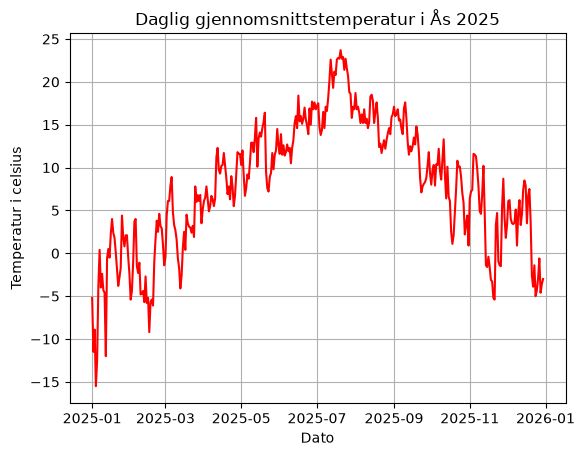

       Mean  Median   Min   Max
0  7.902747     8.4 -15.5  23.7


In [10]:
# Imported libraries
import requests # HTTP library for making requests to the Frost API
import pandas as pd # Organizes and analyzes the weather data
import yaml # Structures data into a .yml file for easy reading and sharing
import matplotlib.pyplot as plt # Visualizes the data in a graph
import matplotlib.dates as mdates  # Formats dates on the x-axis

# Read the client ID from a text file outside the repository  
# with open('C:/Users/Selin/OneDrive/NMBU/2.år/INF201/Frost_API.txt', 'r') as infile:
    # client_id = infile.read().strip()
with open('/Users/kachinaaschenberg/Documents/NMBU/INF201/Frost_API.txt', 'r') as infile:
    client_id = infile.read().strip()


def frost_request(client_id: str, sources: str, elements: str, referencetime: str) -> pd.DataFrame:
    '''
        Gets data from the Frost API and returns a pandas DataFrame in YAML format
        (same function as in Task 1, based on MET's Python example)
        Args:
            client_id (str): Client ID for the Frost API.
            sources (str): Station ID, e.g., 'SN17850'.
            elements (str): Element, e.g., 'mean(air_temperature P1D)'
            referencetime (str): Time range, e.g., '2025-01-01/2025-12-31'.
        Returns:
            pd.DataFrame: DataFrame containing the requested data from the Frost API.
        '''
    
    # Define the endpoint and parameters for the API request
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': sources,
        'elements': elements,
        'referencetime': referencetime,
        'timeoffsets': 'default',
    }

    # HTTP GET request to Frost API with authentication using the client ID
    r = requests.get(endpoint, params=parameters, auth=(client_id, ''))

    # Check if the request was successful (status code 200)
    if r.status_code != 200:
        print(f'Feil {r.status_code}: {r.json()}')
        return None

    data = r.json()

    if 'data' not in data:
        print('Ingen data mottatt')
        return None

    # Check if the response contains data
    records = [] # List to store the records from the API response
    for item in data['data']: # Iterate through each item in the 'data' field of the JSON response
        date = item['referenceTime']
        value = item['observations'][0]['value']
        records.append((date, value))

   

    df = pd.DataFrame(records, columns=['date', 'value']) # Create a pandas df from the records list
    df['date'] = pd.to_datetime(df['date']) # Convert the 'date' column to datetime format for an easier analysis
    
    return df


# Get the data for 2025 from the Frost API
df = frost_request(
    client_id=client_id,
    sources='SN17850',
    elements='mean(air_temperature P1D)',
    referencetime='2025-01-01/2025-12-31'
)

# Plot the data
plt.plot(df['date'], df['value'], color='red')
plt.title('Daglig gjennomsnittstemperatur i Ås 2025')
plt.xlabel('Dato')
plt.ylabel('Temperatur i celsius')
plt.grid(True)
plt.show()

# Make a summary table
summary = {
    'Mean': df['value'].mean(),
    'Median': df['value'].median(),
    'Min': df['value'].min(),
    'Max': df['value'].max(),
}

summary_df = pd.DataFrame(summary, index=[0])
print(summary_df)

Diskuter resultatene

Task 2:

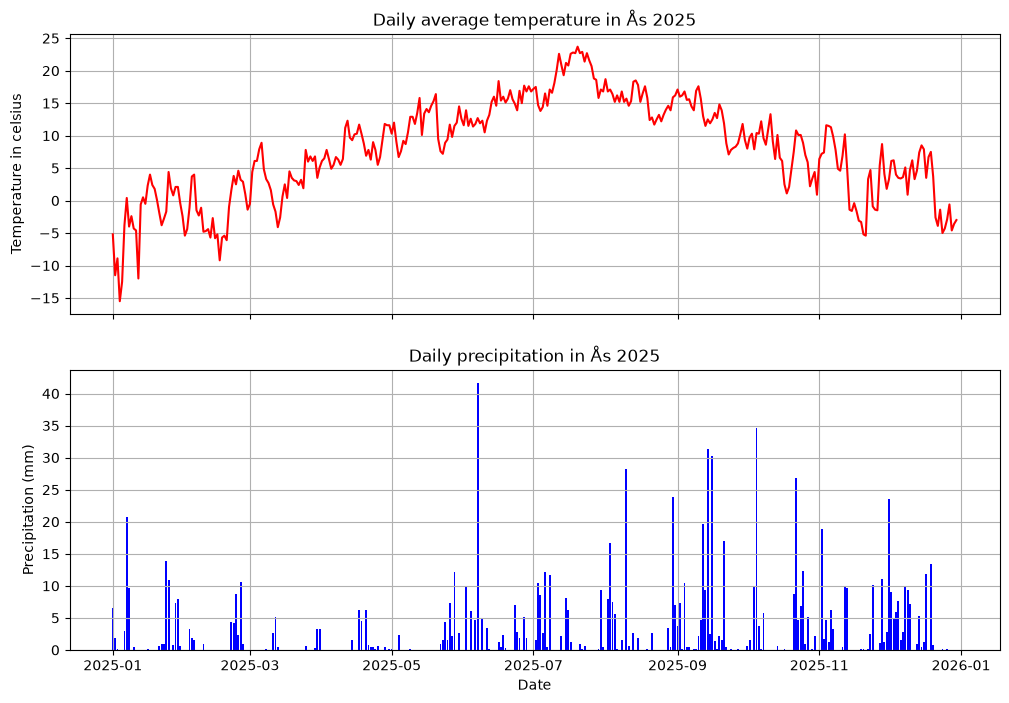

In [11]:
df_temp = frost_request(
    client_id=client_id,
    sources="SN17850",
    elements="mean(air_temperature P1D)",
    referencetime="2025-01-01/2025-12-31"
)

df_rain = frost_request(
    client_id=client_id,
    sources="SN17850",
    elements="sum(precipitation_amount P1D)",
    referencetime="2025-01-01/2025-12-31"
)

fig, ax = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Temperature
ax[0].plot(df_temp['date'], df_temp['value'], color='red')
ax[0].set_title('Daily average temperature in Ås 2025')
ax[0].set_ylabel('Temperature in celsius')
ax[0].grid(True)

# Precipitation
ax[1].bar(df_rain['date'], df_rain['value'], color='blue')
ax[1].set_title('Daily precipitation in Ås 2025')
ax[1].set_ylabel('Precipitation (mm)')
ax[1].grid(True)

plt.xlabel('Date')
plt.show()


diskutere resultatene her

Task 3:

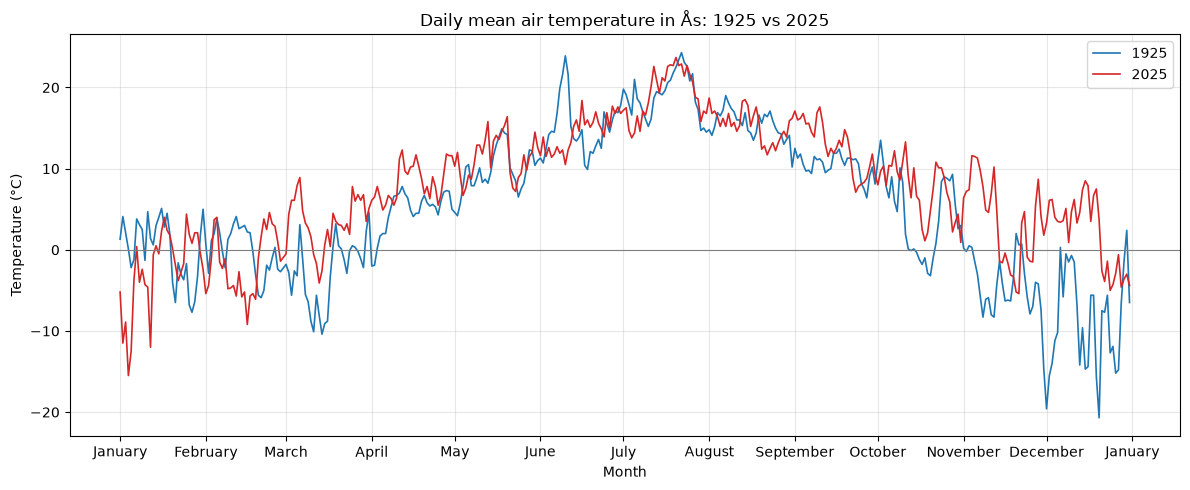

      Mean  Median   Min   Max
1925   5.3     5.3 -20.7  24.3
2025   7.9     8.3 -15.5  23.7


In [12]:
# Imported libraries
import matplotlib.dates as mdates  # Formats dates on the x-axis


def get_mean_temperature(client_id: str, station_id: str, year: int) -> pd.DataFrame | None:
    '''
    Helper function that calls frost_request with the right parameters.
    Gets the daily mean air temperature for one station a whole year.

    Args:
        client_id (str): Personal client ID for the Frost API.
        station_id (str): Station ID, e.g. 'SN17850'.
        year (int): Year to get data from, e.g. 1925.

    Returns:
        pd.DataFrame | None: DataFrame with the columns 'date' and 'value',
        or None if the request failed.
    '''
    return frost_request(client_id, station_id, 'mean(air_temperature P1D)',
                         f'{year}-01-01/{year + 1}-01-01')


def summary_table(data: dict[str, pd.DataFrame]) -> pd.DataFrame:
    '''
    Makes a summary table with mean, median, min and max temperature for each year in the dictionary.

    Args:
        data (dict[str, pd.DataFrame]): Maps a label like '1925' to a DataFrame
            with a 'value' column.

    Returns:
        pd.DataFrame: One row per label and one column per statistic,
        rounded to one decimal.
    '''

    # Create a dictionary to hold the summary statistics for each label
    rows = {}
    for label, df in data.items(): # Iterate through each label and its corresponding df in the dictionary
        rows[label] = {
            'Mean': df['value'].mean(),
            'Median': df['value'].median(),
            'Min': df['value'].min(),
            'Max': df['value'].max(),
        } 
    return pd.DataFrame(rows).T.round(1) 


# Get the data for both years
df_1925 = get_mean_temperature(client_id, 'SN17850', 1925)
df_2025 = get_mean_temperature(client_id, 'SN17850', 2025)

# Plot both years on the same calendar axis (month), so they can be compared 
fig, ax = plt.subplots(figsize=(12, 5)) # Gives a figure and axis for the plot with a set size
ax.plot(df_1925['date'].apply(lambda d: d.replace(year=2000)), df_1925['value'], color='tab:blue', label='1925', linewidth=1.2) # Plot the temperature values for each year with  color and label
ax.plot(df_2025['date'].apply(lambda d: d.replace(year=2000)), df_2025['value'], color='tab:red', label='2025', linewidth=1.2) # Plot the temperature values for each year with color and label


ax.xaxis.set_major_locator(mdates.MonthLocator()) # Set the x-axis to each month
ax.xaxis.set_major_formatter(mdates.DateFormatter('%B')) # Format the x-axis labels to show the whole month name 
ax.axhline(0, color='grey', linewidth=0.8)  # line at 0 °C 
ax.set_title('Daily mean air temperature in Ås: 1925 vs 2025') # Set the title of the plot
ax.set_xlabel('Month') # Set the label for the x-axis
ax.set_ylabel('Temperature (°C)') # Set the label for the y-axis
ax.grid(True, alpha=0.3) # Enable grid lines on the plot with a specified transparency
ax.legend() # Add a legend to the plot to identify the lines for each year
plt.tight_layout() # Prevent overlapping elements
plt.show() # Display the plot

# Summary table for both years
print(summary_table({'1925': df_1925, '2025': df_2025}))


Beskrivelse av task 3: 


Task 4:

In [13]:
def find_heatwaves(df: pd.DataFrame, threshold: float = 27.0, min_days: int = 5) -> list:
    '''
    Finds periods where the maximum temperature is >= threshold for at least min_days consecutive days
    Args:
        df (pd.DataFrame): DataFrame containing the temperature data with 'date' and 'value' columns.
        threshold (float): Temperature threshold to define a heatwave (default is 27.0 degrees).
        min_days (int): Minimum number of consecutive days to define a heatwave (default is 5 days).
    Returns:
        list: List of (start_date, end_date) for each heatwave
    '''

    # Filter the df to only include days temperature is above the threshold
    hot = df[df['value'] >= threshold].sort_values('date')

    # Hot days get put into periods of consecutive days (group 1, group 2, etc.)
    new_period = hot['date'].diff() != pd.Timedelta(days=1) # New period starts when its more than one day since the previous hot day 
    period_id = new_period.cumsum() # assigns group numbers to each period of consecutive hot days


    # Create a list of heatwaves that are at least 5 days long
    heatwaves = []
    for _, period in hot.groupby(period_id): # Iterate through each group of consecutive hot days
        if len(period) >= min_days: # If the period is at least 5 days long, add it to the heatwaves list
            heatwaves.append((period['date'].iloc[0], period['date'].iloc[-1])) # Append a tuple of (start_date, end_date) to the heatwaves list
    return heatwaves

def count_heatwaves(client_id: str, station_id: str, station_name: str, year: int, filename: str = None) -> int: 
    '''
    Counts the number of heatwaves for a station in a given year and writes a summary to a YAML file
    Args:
        client_id (str): Client ID for the Frost API.
        station_id (str): Station ID, e.g., 'SN17850'.
        station_name (str): Name of the station, e.g., 'Ås'.
        year (int): Year for which to count heatwaves, e.g., 2025
        filename (str): Optional filename for the YAML summary file. If None, a default name
    Returns:
        int: Number of heatwaves found for the specified station and year.
    '''

    # Get the maximum temperature data for the specified station and year
    df_max = frost_request(client_id, station_id, 'max(air_temperature P1D)', 
                           f'{year}-01-01/{year}-12-31') 
    if df_max is None:
        return 0

    # Find heatwaves in the data
    heatwaves = find_heatwaves(df_max)

    # Write a summary of the heatwaves to a YAML file, including set parameters and the number of heatwaves found
    summary = {
        'dates': [f'{start:%Y-%m-%d} - {end:%Y-%m-%d}' for start, end in heatwaves],
        'station_id': station_id,
        'station_name': station_name,
        'year': year,
    }
    # Creates a default filename based on the station ID and year if no name is provided
    if filename is None:
        filename = f'heatwaves_{station_id}_{year}.yml'

    # Write the summary to a YAML file
    with open(filename, 'w') as outfile:
        yaml.dump(summary, outfile)

    # Return the number of heatwaves found
    return len(heatwaves)

# Example usage of the count_heatwaves function
n = count_heatwaves(client_id, 'SN17850', 'Ås', 2025)
print(f'Antall hetebølger i Ås i 2025: {n}')


Antall hetebølger i Ås i 2025: 1


Beskrivelse av task 4: Heatwaves
In Norway, a heatwave is a period of *five or more consecutive days* where the
**daily maximum temperature is ≥ 27 °C**. We wrote a function that counts the
heatwaves for any station and year, and writes a summary to a YAML file.

Task 5:

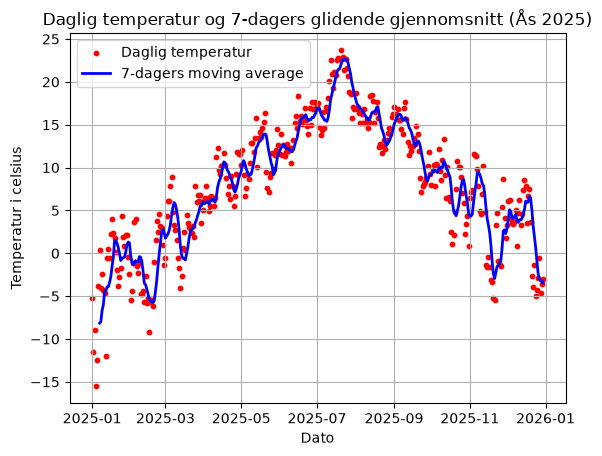

In [14]:
def moving_average(df: pd.DataFrame, window: int = 7) -> pd.DataFrame:
    '''
    Calculates a moving average of the temperature over a specified number of days.
    Args:
        df (pd.DataFrame): DataFrame containing 'date' and 'value' columns.
        window (int): Number of days to include in the moving average.
    Returns:
        pd.DataFrame: A copy of the DataFrame with an additional 'moving_avg' column
    '''
    df_ma = df.copy()
    df_ma['moving_avg'] = df_ma['value'].rolling(window=window).mean()
    return df_ma


df_temp_ma = moving_average(df_temp, window=7)


# Daily temperature as scatter plot
plt.scatter(df_temp_ma['date'], df_temp_ma['value'], color='red', s=10, label='Daglig temperatur')

# Moving average as line
plt.plot(df_temp_ma['date'], df_temp_ma['moving_avg'], color='blue', linewidth=2, label='7-dagers moving average')

plt.title('Daglig temperatur og 7-dagers glidende gjennomsnitt (Ås 2025)')
plt.xlabel('Dato')
plt.ylabel('Temperatur i celsius')
plt.legend()
plt.grid(True)
plt.show()


beskrivelse av resultatene